In [1]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

In [2]:
#data download:
#!/bin/bash
!kaggle datasets download -d arwabasal/brain-tumor-mri-detection

Dataset URL: https://www.kaggle.com/datasets/arwabasal/brain-tumor-mri-detection
License(s): MIT
100% 15.1M/15.1M [00:00<00:00, 101MB/s] 



In [3]:
#unzip:
import zipfile
zip_ref = zipfile.ZipFile('/content/brain-tumor-mri-detection.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

In [13]:
#loading libraries:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,BatchNormalization,Dense,Flatten, Dropout,GlobalAveragePooling2D, MaxPooling2D
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow import keras
from matplotlib import pyplot as plt
from tensorflow.keras.regularizers import l1, l2
import keras_tuner as kt


In [10]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [keras-tuner]


In [7]:
#generators :
train_ds = keras.utils.image_dataset_from_directory(
    directory = "/content/brain_tumor_dataset",
    labels = "inferred",
    label_mode = "int",
    image_size = (256,256),
    batch_size = 32,
    validation_split = 0.2,
    subset  = "training",
    seed = 42
)

val_ds = keras.utils.image_dataset_from_directory(
    directory = "/content/brain_tumor_dataset",
    labels = "inferred",
    label_mode = "int",
    image_size = (256,256),
    batch_size = 32,
    validation_split = 0.2,
    subset  = "validation",
    seed = 42
)

Found 253 files belonging to 2 classes.
Using 203 files for training.
Found 253 files belonging to 2 classes.
Using 50 files for validation.


In [8]:
#normalization:
def process(image, label):
  image = tf.cast(image/255., tf.float32)
  return image, label
train_ds = train_ds.map(process)
val_ds = val_ds.map(process)

In [14]:
def build_model(hp):
  model = Sequential()
  model.add(Conv2D(filters = hp.Choice("filter1", values = [32,64,128]),
                   kernel_size = (3,3),
                   padding = "same",
                   activation = "sigmoid",
                   input_shape = (256,256,3)))
  model.add(BatchNormalization())
  model.add(MaxPooling2D(pool_size = (2,2)))

  #h1:
  model.add(Conv2D(filters = hp.Choice("filter2", values = [64, 128,256]),
                   kernel_size = (3,3),
                   padding = "same",
                   activation = "relu"))
  model.add(BatchNormalization())
  model.add(MaxPooling2D(pool_size = (2,2)))

  #h2:
  model.add(Conv2D(filters = hp.Choice("filter3", values = [128,256,512]),
                   kernel_size = (3,3),
                   padding = "same",
                   activation = "relu"))
  model.add(BatchNormalization())
  model.add(MaxPooling2D(pool_size = (2,2)))

  #h3:
  model.add(Conv2D(filters = hp.Choice("filter4", values = [128,256,512]),
                   kernel_size = (3,3),
                   padding = "same",
                   activation = "relu"))
  model.add(BatchNormalization())
  model.add(MaxPooling2D(pool_size = (2,2)))

  model.add(Flatten())
  model.add(Dense(units = hp.Choice("unit1", values = [128,256,512]),
                  activation = "relu"))
  model.add(Dropout(rate = hp.Choice("dropout", values = [0.1,0.2,0.3,0.4,0.5])))\

  model.add(Dense(1, activation = "sigmoid"))

  model.compile(optimizer = Adam(learning_rate = hp.Choice("learning_rate", values = [0.001,0.0001])),
                loss = "binary_crossentropy",
                metrics = ["accuracy"])
  return  model

In [16]:
tuner = kt.Hyperband(
 build_model,
 objective = kt.Objective("val_accuracy", direction = "max"),
 factor = 3,
 max_epochs= 20,
 directory = "my_tuner",
 overwrite = True
)
tuner.search_space_summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Search space summary
Default search space size: 7
filter1 (Choice)
{'default': 32, 'conditions': [], 'values': [32, 64, 128], 'ordered': True}
filter2 (Choice)
{'default': 64, 'conditions': [], 'values': [64, 128, 256], 'ordered': True}
filter3 (Choice)
{'default': 128, 'conditions': [], 'values': [128, 256, 512], 'ordered': True}
filter4 (Choice)
{'default': 128, 'conditions': [], 'values': [128, 256, 512], 'ordered': True}
unit1 (Choice)
{'default': 128, 'conditions': [], 'values': [128, 256, 512], 'ordered': True}
dropout (Choice)
{'default': 0.1, 'conditions': [], 'values': [0.1, 0.2, 0.3, 0.4, 0.5], 'ordered': True}
learning_rate (Choice)
{'default': 0.001, 'conditions': [], 'values': [0.001, 0.0001], 'ordered': True}


In [18]:
tuner.search(
    train_ds,
    epochs = 20,
    validation_data = val_ds,
    callbacks = [EarlyStopping(monitor = "val_loss", patience = 3)
])

Trial 26 Complete [00h 00m 20s]

Best val_accuracy So Far: 0.7599999904632568
Total elapsed time: 00h 19m 32s


In [19]:
best_hps = tuner.get_best_hyperparameters(num_trials =1)[0]
print('Best values found by Keras Tuner:')
print('=================================')
print('Block 1 filters :', best_hps.get('filter1'))
print('Block 2 filters :', best_hps.get('filter2'))
print('Block 3 filters :', best_hps.get('filter3'))
print('Block 4 filters :', best_hps.get('filter4'))
print('Dense units     :', best_hps.get('unit1'))
print('Dropout rate    :', best_hps.get('dropout'))
print('Learning rate   :', best_hps.get('learning_rate'))

Best values found by Keras Tuner:
Block 1 filters : 32
Block 2 filters : 64
Block 3 filters : 256
Block 4 filters : 256
Dense units     : 256
Dropout rate    : 0.4
Learning rate   : 0.001


In [25]:
best_model = tuner.hypermodel.build(best_hps)
best_model.summary()

final_early_stopping = EarlyStopping(monitor = "val_loss",
                                     mode = "min",
                                     patience = 5,
                                     restore_best_weights = True)
history = best_model.fit(train_ds, epochs = 50,
                         validation_data = val_ds,
                        callbacks = [final_early_stopping])

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 64, 64, 256)    │       147,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 64, 64, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │    16,777,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,537,345 (66.90 MB)

 Trainable params: 17,536,129 (66.90 MB)

 Non-trainable params: 1,216 (4.75 KB)

Epoch 1/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.5813 - loss: 20.0875 - val_accuracy: 0.6600 - val_loss: 1.2039
Epoch 2/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 149ms/step - accuracy: 0.6798 - loss: 2.2607 - val_accuracy: 0.5000 - val_loss: 0.7114
Epoch 3/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 134ms/step - accuracy: 0.7980 - loss: 0.8244 - val_accuracy: 0.3400 - val_loss: 3.8559
Epoch 4/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 129ms/step - accuracy: 0.7734 - loss: 0.7652 - val_accuracy: 0.3400 - val_loss: 21.9454
Epoch 5/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 133ms/step - accuracy: 0.7635 - loss: 0.5566 - val_accuracy: 0.3400 - val_loss: 20.6164
Epoch 6/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 139ms/step - accuracy: 0.8128 - loss: 0.4493 - val_accuracy: 0.3400 - val_loss: 20.7622
Epoch 7/50
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 140ms/step - accuracy: 0.7931 - loss: 0.4949 - val_accuracy: 0.3400 - val_loss: 13.8845


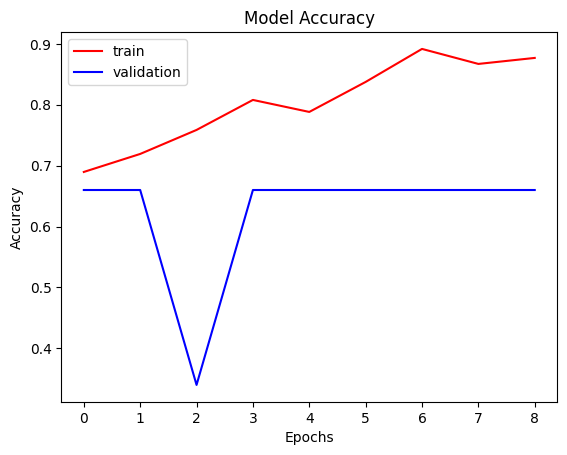

In [22]:
# STEP 13 - Plot Accuracy
plt.plot(history.history['accuracy'], color='red', label='train')
plt.plot(history.history['val_accuracy'], color='blue', label='validation')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

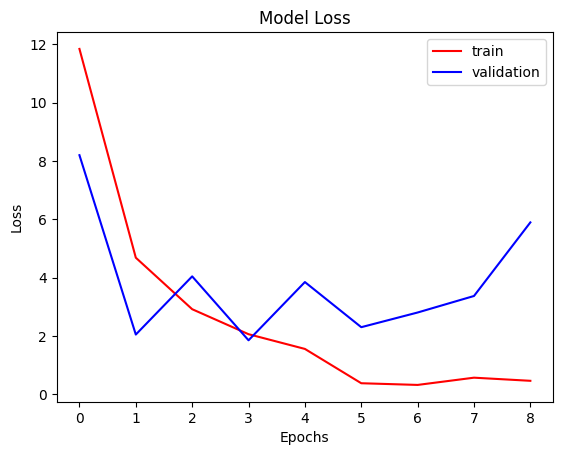

In [23]:
# STEP 14 - Plot Loss
plt.plot(history.history['loss'], color='red', label='train')
plt.plot(history.history['val_loss'], color='blue', label='validation')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()